Project Title : AI-Based Vehicle Fuel Efficiency Anomaly Detection

Subtitle:
Using Machine Learning to Identify Unusual Vehicle Fuel Efficiency Patterns

Problem Statement:
Identifying unusual vehicle fuel-efficiency patterns manually is difficult when dealing with large amounts of vehicle data.

Objectives:
1. Collect vehicle-related data
2. Clean and preprocess the dataset
3. Analyze vehicle and fuel-efficiency patterns
4. Identify factors affecting fuel efficiency
5. Detect unusual fuel-efficiency observations
6. Apply machine learning for anomaly detection
7. Generate useful insights from the results

In [2]:
#import pandas and load a dataset
import pandas as pd
df=pd.read_csv(r"vehicle_fuel_efficiency_2000.csv")

Data is collected from California open data

California Air Resources Board — Vehicle Fuel Economy

Official source:  California Open Data — Vehicle Fuel Economy

Dataset information

Number of records: 2000

Number of columns: 17

File format: CSV

Domain: Vehicle / Automotive

Target/important variable: Fuel Efficiency

In [3]:
#Creating copy of raw data for backup and another copy of data for cleaning process
raw_df=df.copy()
clean_df=df.copy()

In [4]:
#Display total number of rows and cols in a dataset
print("Total Number of Rows and Columns in a dataset is: ")
clean_df.shape

Total Number of Rows and Columns in a dataset is: 


(2000, 17)

In [5]:
#Display few records
clean_df.head(3)

,make,model,year,VClass,drive,trany,cylinders,displ,fuelType1,city08,highway08,comb08,fuelCost08,barrels08,co2TailpipeGpm,UCity,UHighway
0,Ford,Freestar Wagon FWD,2004,Minivan - 2WD,Front-Wheel Drive,Automatic 4-spd,6.0,4.2,Regular Gasoline,15,21,17,2350,19.388824,522.764706,18.100,28.8478
1,Honda,Element 4WD,2009,Sport Utility Vehicle - 4WD,4-Wheel or All-Wheel Drive,Automatic 5-spd,4.0,2.4,Regular Gasoline,19,24,21,1900,15.695714,423.190476,23.800,33.5000
2,Audi,A4,1999,Compact Cars,Front-Wheel Drive,Automatic 5-spd,6.0,2.8,Premium Gasoline,16,27,20,2500,16.480500,444.350000,19.982,37.2494


In [6]:
#Display dataset information
print("Information of a Dataset")
clean_df.info()

Information of a Dataset
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   make            2000 non-null   str    
 1   model           2000 non-null   str    
 2   year            2000 non-null   int64  
 3   VClass          2000 non-null   str    
 4   drive           1944 non-null   str    
 5   trany           2000 non-null   str    
 6   cylinders       1996 non-null   float64
 7   displ           1996 non-null   float64
 8   fuelType1       2000 non-null   str    
 9   city08          2000 non-null   int64  
 10  highway08       2000 non-null   int64  
 11  comb08          2000 non-null   int64  
 12  fuelCost08      2000 non-null   int64  
 13  barrels08       2000 non-null   float64
 14  co2TailpipeGpm  2000 non-null   float64
 15  UCity           2000 non-null   float64
 16  UHighway        2000 non-null   float64
dtypes: float64(6), int6

In [ ]:
#Dataset contains some missing values , target is to filling and cleaning missing values

In [50]:
#TO describe(count,mean,max,min,etc...) the data in the dataset
clean_df.describe()

,Model_Year,Cylinders,Engine_Displacement,City_MPG,Highway_MPG,Combined_MPG,Annual_Fuel_Cost,Petroleum_Consumption,CO2_Emissions,Adjusted_City_MPG,Adjusted_Highway_MPG
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,2001.336500,5.769500,3.353500,17.932500,24.075500,20.177500,2304.050000,17.556475,473.312451,22.604249,33.688450
std,10.979642,1.758384,1.347993,6.666721,6.931654,6.649669,636.395001,4.555252,122.314203,9.502670,10.253287
min,1984.000000,2.000000,0.600000,7.000000,9.000000,8.000000,500.000000,0.116250,0.000000,0.000000,0.000000
25%,1991.000000,4.000000,2.300000,15.000000,20.000000,17.000000,1850.000000,14.330870,389.000000,18.094600,27.347975
50%,2002.000000,6.000000,3.000000,17.000000,24.000000,19.000000,2250.000000,17.347895,465.500000,21.024100,33.000000
75%,2011.000000,6.000000,4.300000,20.000000,27.000000,23.000000,2700.000000,19.570368,535.197368,25.048700,38.024475
max,2019.000000,12.000000,8.400000,150.000000,122.000000,136.000000,6250.000000,41.201250,1110.875000,224.800000,182.700000


In [7]:
#Display all column names
clean_df.columns

Index(['make', 'model', 'year', 'VClass', 'drive', 'trany', 'cylinders',
       'displ', 'fuelType1', 'city08', 'highway08', 'comb08', 'fuelCost08',
       'barrels08', 'co2TailpipeGpm', 'UCity', 'UHighway'],
      dtype='str')

Data Cleaning Process

Our Project involves these steps of Data cleaning Process

1.Renaming and remove extra spaces in column names

2.checking missing values and filling values by using fillna() and ffill() functions

3.Identifying and removing duplicated rows

4.checking Inconsistent values and rename it

In [9]:
#renaming column names in meaningful variable
clean_df = clean_df.rename(columns={
    "make": "Manufacturer",
    "model": "Model",
    "year": "Model_Year",
    "VClass": "Vehicle_Class",
    "drive": "Drive_Type",
    "trany": "Transmission",
    "cylinders": "Cylinders",
    "displ": "Engine_Displacement",
    "fuelType1": "Fuel_Type",
    "city08": "City_MPG",
    "highway08": "Highway_MPG",
    "comb08": "Combined_MPG",
    "fuelCost08": "Annual_Fuel_Cost",
    "barrels08": "Petroleum_Consumption",
    "co2TailpipeGpm": "CO2_Emissions",
    "UCity": "Adjusted_City_MPG",
    "UHighway": "Adjusted_Highway_MPG"
})
clean_df.columns

Index(['Manufacturer', 'Model', 'Model_Year', 'Vehicle_Class', 'Drive_Type',
       'Transmission', 'Cylinders', 'Engine_Displacement', 'Fuel_Type',
       'City_MPG', 'Highway_MPG', 'Combined_MPG', 'Annual_Fuel_Cost',
       'Petroleum_Consumption', 'CO2_Emissions', 'Adjusted_City_MPG',
       'Adjusted_Highway_MPG'],
      dtype='str')

In [12]:
#removing extra spaces in a column names
clean_df.columns = clean_df.columns.str.strip()
clean_df.columns

Index(['Manufacturer', 'Model', 'Model_Year', 'Vehicle_Class', 'Drive_Type',
       'Transmission', 'Cylinders', 'Engine_Displacement', 'Fuel_Type',
       'City_MPG', 'Highway_MPG', 'Combined_MPG', 'Annual_Fuel_Cost',
       'Petroleum_Consumption', 'CO2_Emissions', 'Adjusted_City_MPG',
       'Adjusted_Highway_MPG'],
      dtype='str')

In [13]:
#Checking missing values in a datset
print("Missing values in each columns")
clean_df.isnull().sum()

Missing values in each columns


Manufacturer              0
Model                     0
Model_Year                0
Vehicle_Class             0
Drive_Type               56
Transmission              0
Cylinders                 4
Engine_Displacement       4
Fuel_Type                 0
City_MPG                  0
Highway_MPG               0
Combined_MPG              0
Annual_Fuel_Cost          0
Petroleum_Consumption     0
CO2_Emissions             0
Adjusted_City_MPG         0
Adjusted_Highway_MPG      0
dtype: int64

In [14]:
#Filling missing values
clean_df["Drive_Type"]=clean_df["Drive_Type"].fillna("Unknown")
clean_df["Cylinders"]=clean_df["Cylinders"].ffill()
clean_df["Engine_Displacement"]=clean_df["Engine_Displacement"].ffill()

In [15]:
#After filling missing values
print("Afetr filling Missing values in each columns")
clean_df.isnull().sum()

Afetr filling Missing values in each columns


Manufacturer             0
Model                    0
Model_Year               0
Vehicle_Class            0
Drive_Type               0
Transmission             0
Cylinders                0
Engine_Displacement      0
Fuel_Type                0
City_MPG                 0
Highway_MPG              0
Combined_MPG             0
Annual_Fuel_Cost         0
Petroleum_Consumption    0
CO2_Emissions            0
Adjusted_City_MPG        0
Adjusted_Highway_MPG     0
dtype: int64

In [18]:
#Identifying duplicated rows
print("Duplicated rows in a dataset:  ",clean_df.duplicated().sum())

Duplicated rows in a dataset:   2


In [20]:
clean_df[clean_df.duplicated()]  # It is not same rows hence we don't want to remove from the dataset

,Manufacturer,Model,Model_Year,Vehicle_Class,Drive_Type,Transmission,Cylinders,Engine_Displacement,Fuel_Type,City_MPG,Highway_MPG,Combined_MPG,Annual_Fuel_Cost,Petroleum_Consumption,CO2_Emissions,Adjusted_City_MPG,Adjusted_Highway_MPG
639,Chevrolet,Equinox AWD,2017,Small Sport Utility Vehicle 4WD,All-Wheel Drive,Automatic 6-spd,4.0,2.4,Regular Gasoline,20,28,23,1750,14.330870,381.000000,25.8453,40.1978
1797,Chevrolet,T10 (S10) Blazer 4WD,1984,Special Purpose Vehicle 4WD,4-Wheel or All-Wheel Drive,Manual 5-spd,6.0,2.8,Regular Gasoline,15,22,17,2350,19.388824,522.764706,18.0000,30.0000


In [35]:
#Checking Inconsistent category
clean_df["Fuel_Type"].unique()

<ArrowStringArray>
[ 'Regular Gasoline',  'Premium Gasoline',            'Diesel',
       'Natural Gas',       'Electricity', 'Midgrade Gasoline']
Length: 6, dtype: str

In [36]:
clean_df["Petroleum_Consumption"].unique()

array([19.38882353, 15.69571429, 16.4805    , 13.1844    , 18.31166667,
       11.77178571, 14.33086957, 12.67730769, 10.987     , 20.600625  ,
       21.974     , 12.20777778, 23.54357143, 22.48147059, 10.56499929,
       13.73375   , 32.961     , 10.84636378, 17.34789474,  9.69441176,
       15.924375  , 29.96454545, 20.115     , 14.98227273, 10.63258065,
       27.4675    ,  8.24025   , 13.64946429, 25.35461538, 10.3003125 ,
       21.2325    ,  9.98818182,  6.2190566 , 11.36586207, 10.91957143,
       17.37204545,  7.16543478, 11.94328125,  9.35399727, 19.10925   ,
        9.15583333, 18.19928571,  7.49113636, 12.7395    ,  8.45153846,
       36.62333333,  6.33865385,  7.84785714,  8.03926829, 41.20125   ,
        0.11625   , 23.8865625 , 11.24073529, 14.155     , 27.29892857,
        0.216     , 25.479     , 10.0575    ,  8.90837838, 10.61625   ,
        0.15      ,  0.168     , 15.2874    , 14.69942308,  1.23807953,
       10.32932432, 16.61673913,  9.41742857,  6.5922    ,  0.22

In [37]:
clean_df["Highway_MPG"].unique()

array([ 21,  24,  27,  32,  22,  33,  30,  19,  34,  17,  16,  20,  23,
        29,  36,  18,  28,  12,  40,  26,  14,  25,  38,  15,  31,  39,
        44,  37,  35,  61,  13,  43,  45,  10,  50,  42,  98,  41, 122,
        11, 111,   9,  46,  94])

In [38]:
#There is no inconsistentcy in any column in the dataset

Saving Cleaned Dataset

In [42]:
#Saving the cleaned dataset
clean_df.to_csv("vehicle_fuel_efficiency_2000_cleaned.csv",index=False)

In [44]:
#checking whether file is  there or not
import os
print(os.path.exists("vehicle_fuel_efficiency_2000_cleaned.csv"))

True


EXPLORATORY DATA ANALYSIS (EDA) Process

To visualise the cleaned dataset by using matplotlib and seaborn

In [52]:
#importing matplotlib for visualization
import matplotlib.pyplot as plt

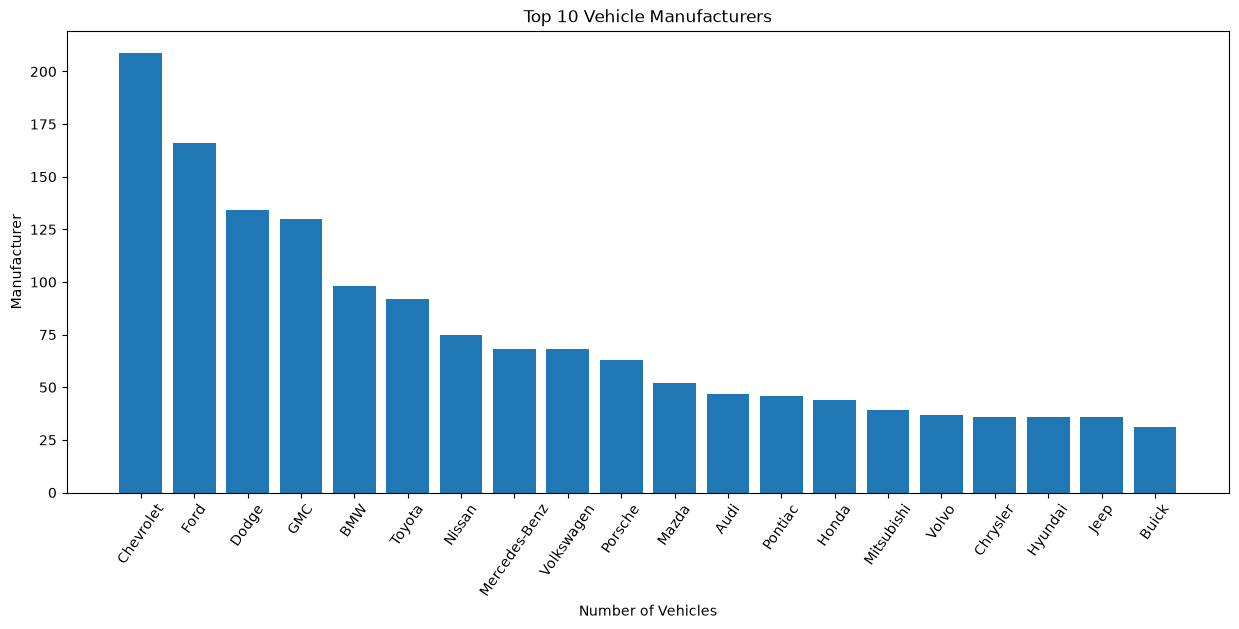

In [57]:
#1. Which manufacturers are most represented
#Visualization: Bar Chart
top_manufacturers = clean_df["Manufacturer"].value_counts().head(20)
plt.figure(figsize=(15, 6))

plt.bar(
    top_manufacturers.index,
    top_manufacturers.values
)

plt.title("Top 10 Vehicle Manufacturers")
plt.xlabel("Number of Vehicles")
plt.ylabel("Manufacturer")
plt.xticks(rotation=55)
plt.show()

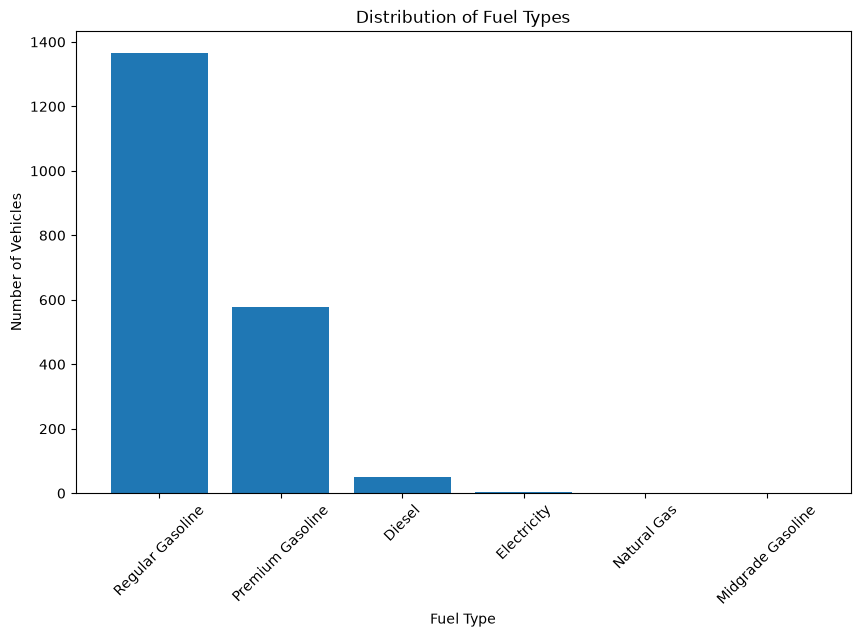

In [58]:
#2. Which fuel types are most common?
# Visualization: Bar Chart
fuel_counts = clean_df["Fuel_Type"].value_counts()
plt.figure(figsize=(10, 6))

plt.bar(
    fuel_counts.index,
    fuel_counts.values
)

plt.title("Distribution of Fuel Types")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Vehicles")
plt.xticks(rotation=45)
plt.show()

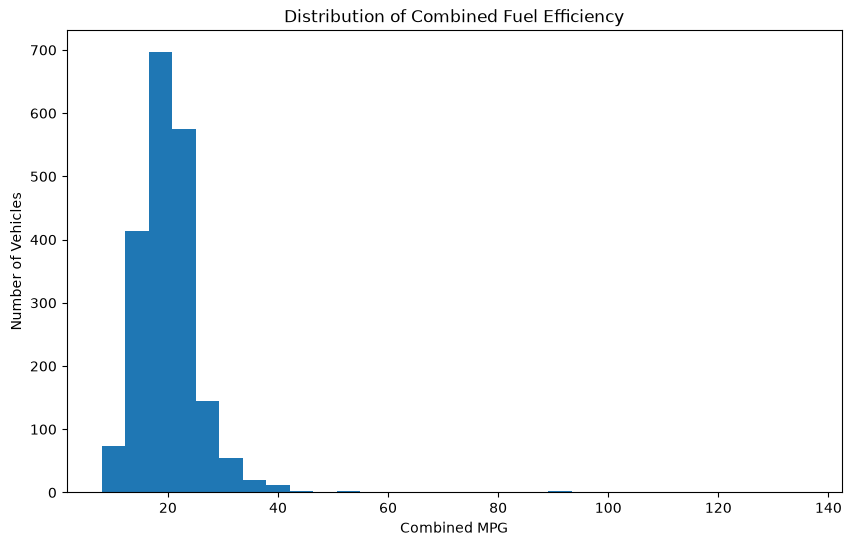

In [60]:
#3. What is the distribution of combined fuel efficiency?
#Visualization: Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    clean_df["Combined_MPG"],
    bins=30
)

plt.title("Distribution of Combined Fuel Efficiency")
plt.xlabel("Combined MPG")
plt.ylabel("Number of Vehicles")
plt.show()

In [64]:
#4. What are the minimum, maximum, mean and median MPG values?
#Visualization: Box Plot + Statistics
print("Minimum:", clean_df["Combined_MPG"].min())
print("Maximum:", clean_df["Combined_MPG"].max())
print("Mean:", clean_df["Combined_MPG"].mean())
print("Median:", clean_df["Combined_MPG"].median())

Minimum: 8
Maximum: 136
Mean: 20.1775
Median: 19.0


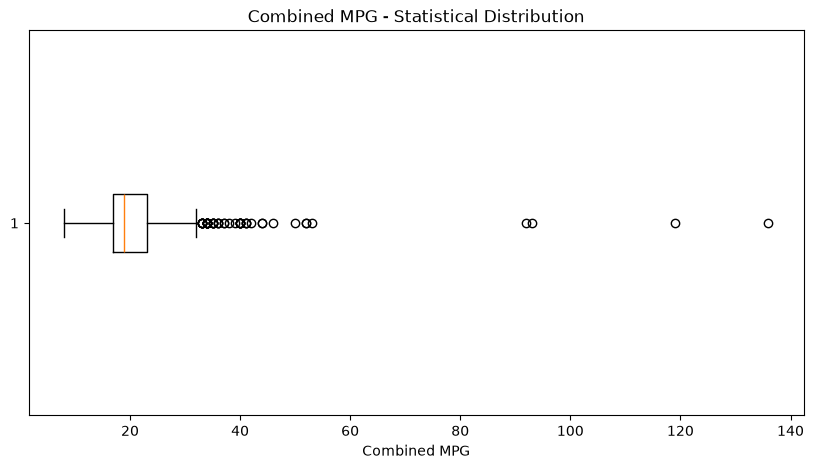

In [66]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    clean_df["Combined_MPG"],
    orientation="horizontal"
)

plt.title("Combined MPG - Statistical Distribution")
plt.xlabel("Combined MPG")
plt.show()

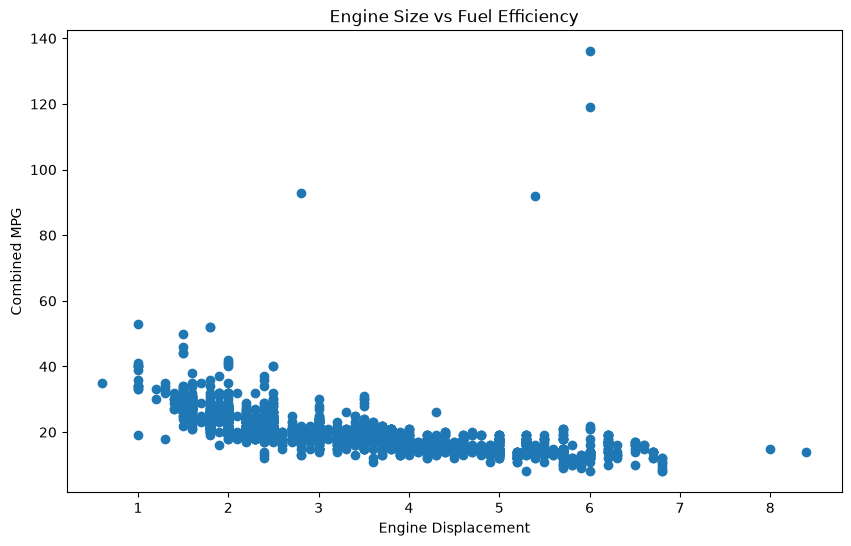

In [68]:
#5. What is the relationship between engine size and fuel efficiency?
#Visualization: Scatter Plot
plt.figure(figsize=(10, 6))

plt.scatter(
    clean_df["Engine_Displacement"],
    clean_df["Combined_MPG"]
)

plt.title("Engine Size vs Fuel Efficiency")
plt.xlabel("Engine Displacement")
plt.ylabel("Combined MPG")
plt.show()

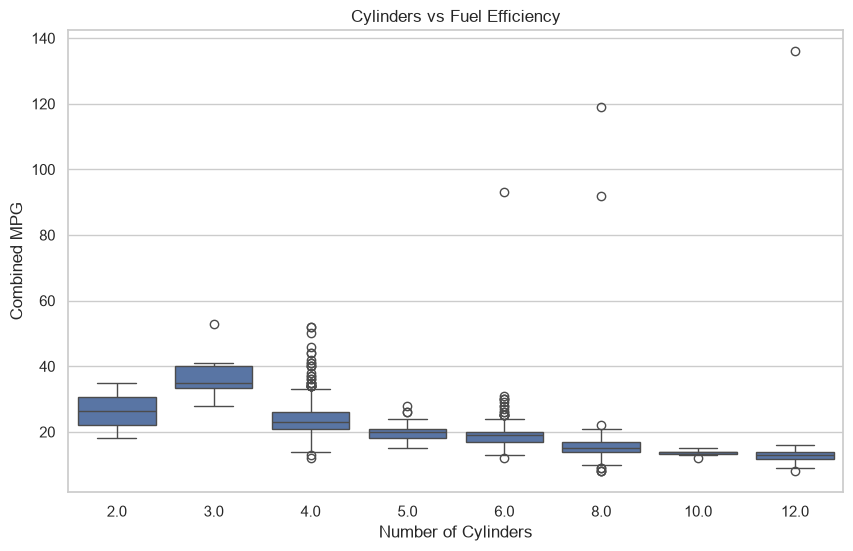

In [75]:
#6. Does cylinder count affect fuel efficiency?
#Visualization: Box Plot
import seaborn as sns
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=clean_df,
    x="Cylinders",
    y="Combined_MPG"
)

plt.title("Cylinders vs Fuel Efficiency")
plt.xlabel("Number of Cylinders")
plt.ylabel("Combined MPG")
plt.show()

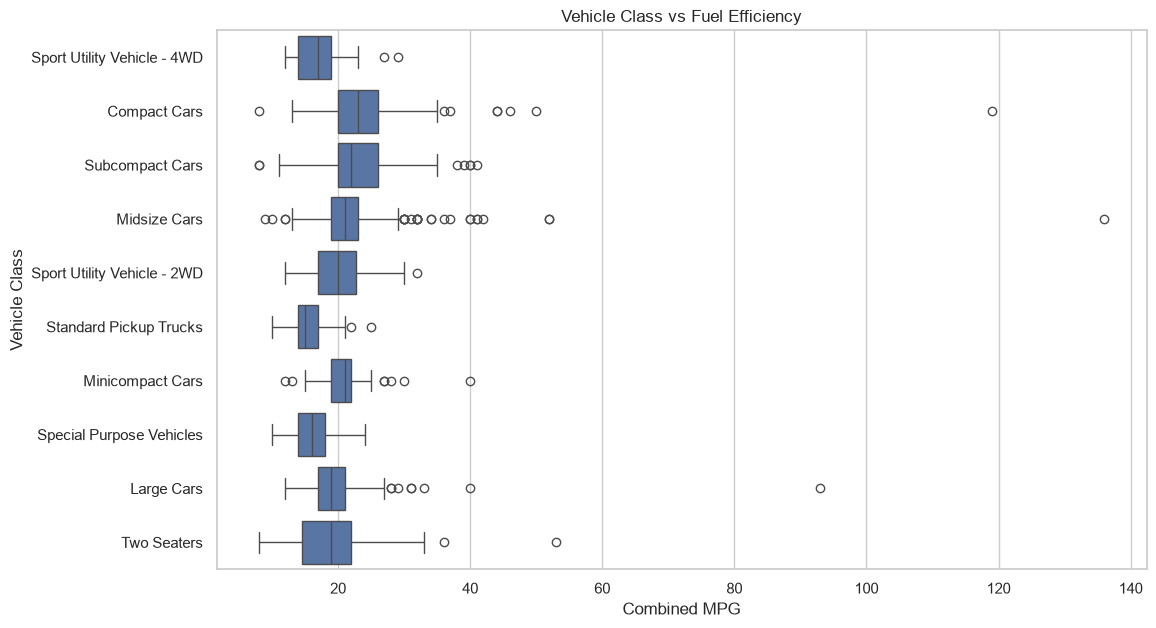

In [80]:
#7. Does vehicle class affect fuel efficiency?
#Visualization: Box Plot

top_classes = (
    clean_df["Vehicle_Class"]
    .value_counts()
    .head(10)
    .index
)

df_class = clean_df[
    clean_df["Vehicle_Class"].isin(top_classes)
]

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_class,
    x="Combined_MPG",
    y="Vehicle_Class"
)

plt.title("Vehicle Class vs Fuel Efficiency")
plt.xlabel("Combined MPG")
plt.ylabel("Vehicle Class")
plt.show()

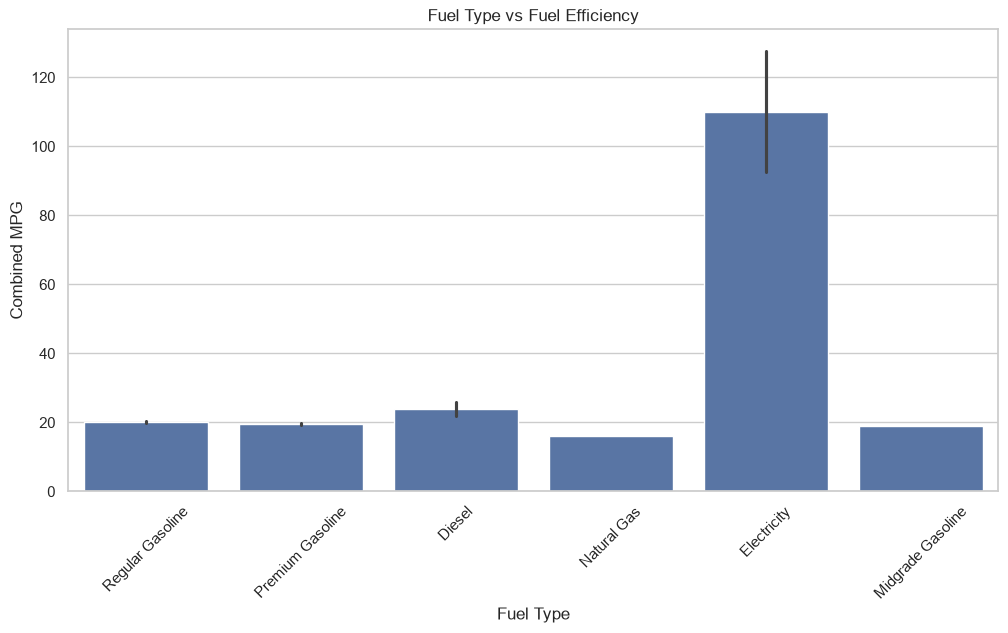

In [82]:
#8. Does fuel type affect fuel efficiency?
#Visualization: Bar Plot
plt.figure(figsize=(12, 6))

sns.barplot(
    data=clean_df,
    x="Fuel_Type",
    y="Combined_MPG"
)

plt.title("Fuel Type vs Fuel Efficiency")
plt.xlabel("Fuel Type")
plt.ylabel("Combined MPG")
plt.xticks(rotation=45)
plt.show()

C:\Users\acer\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


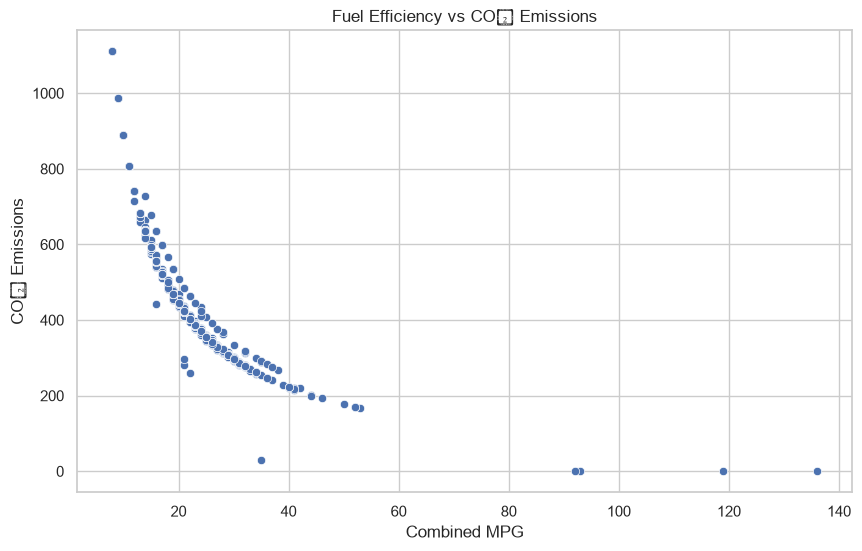

In [83]:
#9. What is the relationship between fuel efficiency and CO₂ emissions?
# Visualization: Scatter Plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean_df,
    x="Combined_MPG",
    y="CO2_Emissions"
)

plt.title("Fuel Efficiency vs CO₂ Emissions")
plt.xlabel("Combined MPG")
plt.ylabel("CO₂ Emissions")
plt.show()

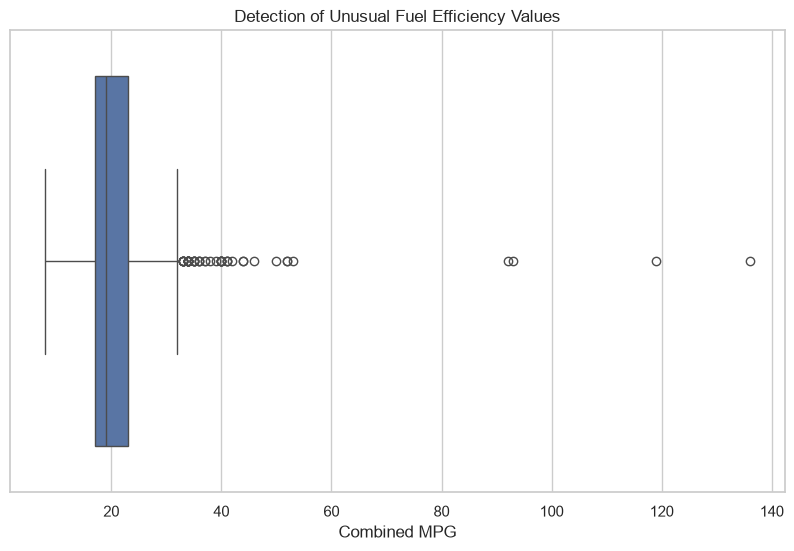

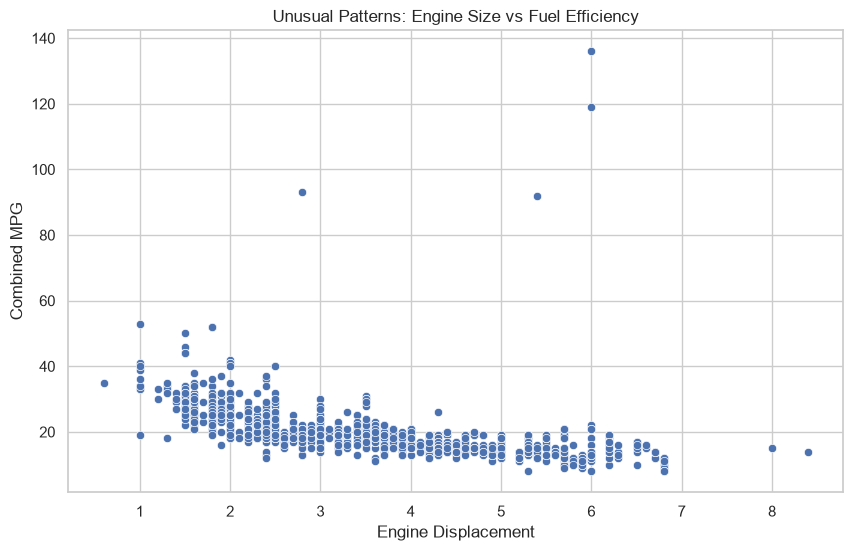

In [86]:
#10. Are there unusual fuel-efficiency patterns
#visualization:  combination of:  Box plot , Scatter plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=clean_df["Combined_MPG"]
)

plt.title("Detection of Unusual Fuel Efficiency Values")
plt.xlabel("Combined MPG")
plt.show()


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean_df,
    x="Engine_Displacement",
    y="Combined_MPG"
)

plt.title("Unusual Patterns: Engine Size vs Fuel Efficiency")
plt.xlabel("Engine Displacement")
plt.ylabel("Combined MPG")
plt.show()

Conclusion

This project analyzes vehicle data to understand fuel-efficiency patterns and identify unusual observations using AI and machine learning techniques.

Project achievements

✅ Dataset collected
✅ Data preprocessing performed
✅ EDA completed
✅ Important patterns identified
